# Importing packages

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder

# Preprocessing data

## Data cleaning

In [109]:
df = pd.read_csv('../Data/Thyroid_Diff.csv')
df.head(3)

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No


In [110]:
df.rename(columns={'Hx Smoking' : 'Smoking History',
                   'Hx Radiothreapy' : 'Radiotherapy History',
                   'Pathology' : 'Types of cancer',
                   'T' : 'Tumor class',
                   'N' : 'Nodal class',
                   'M': 'Metastasis class',
                   'Stage' : 'Cancer stage'}, inplace=True)

In [111]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Smoking History       383 non-null    str  
 4   Radiotherapy History  383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Types of cancer       383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  Tumor class           383 non-null    str  
 12  Nodal class           383 non-null    str  
 13  Metastasis class      383 non-null    str  
 14  Cancer stage          383 non-null    str  
 15  Response              383 non-null    str  
 16  Recurred           

In [ ]:
print(df['Adenopathy'].unique())
print(df['Risk'].unique())

<StringArray>
['No', 'Right', 'Extensive', 'Left', 'Bilateral', 'Posterior']
Length: 6, dtype: str
<StringArray>
['Low', 'Intermediate', 'High']
Length: 3, dtype: str
<StringArray>
['Indeterminate', 'Excellent', 'Structural Incomplete',
 'Biochemical Incomplete']
Length: 4, dtype: str


In [113]:
# Ordinal encoding

risk_mapping = {'Low': 0, 'Intermediate': 1, 'High': 2}
df['Risk'] = df['Risk'].map(risk_mapping)

stage_mapping = {'I': 1, 'II': 2, 'III': 3, 'IVA': 4, 'IVB': 5, 'IVC': 6}
df['Cancer stage'] = df['Cancer stage'].map(stage_mapping)

In [114]:
# Binary mapping

df['Gender'] = df['Gender'].map({'F': 0, 'M': 1})

yes_no_cols = ['Smoking', 'Smoking History', 'Radiotherapy History', 'Recurred']
for col in yes_no_cols:
    df[col] = df[col].map({'No': 0, 'Yes': 1})

In [115]:
# One-hot encoding (for multi-class unordered variables)

nominal_columns = [
    'Thyroid Function', 
    'Physical Examination',
    'Adenopathy',
    'Types of cancer', 
    'Focality', 
    'Tumor class', 
    'Nodal class', 
    'Metastasis class'
]

df = pd.get_dummies(df, columns=nominal_columns, drop_first=True)

In [116]:
# Encoding target

le = LabelEncoder()
df['Response'] = le.fit_transform(df['Response'])

In [117]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 35 columns):
 #   Column                                            Non-Null Count  Dtype
---  ------                                            --------------  -----
 0   Age                                               383 non-null    int64
 1   Gender                                            383 non-null    int64
 2   Smoking                                           383 non-null    int64
 3   Smoking History                                   383 non-null    int64
 4   Radiotherapy History                              383 non-null    int64
 5   Risk                                              383 non-null    int64
 6   Cancer stage                                      383 non-null    int64
 7   Response                                          383 non-null    int64
 8   Recurred                                          383 non-null    int64
 9   Thyroid Function_Clinical Hypothyroidism          383 

In [118]:
df.isnull().sum()

Age                                                 0
Gender                                              0
Smoking                                             0
Smoking History                                     0
Radiotherapy History                                0
Risk                                                0
Cancer stage                                        0
Response                                            0
Recurred                                            0
Thyroid Function_Clinical Hypothyroidism            0
Thyroid Function_Euthyroid                          0
Thyroid Function_Subclinical Hyperthyroidism        0
Thyroid Function_Subclinical Hypothyroidism         0
Physical Examination_Multinodular goiter            0
Physical Examination_Normal                         0
Physical Examination_Single nodular goiter-left     0
Physical Examination_Single nodular goiter-right    0
Adenopathy_Extensive                                0
Adenopathy_Left             

In [119]:
df.duplicated().sum()

np.int64(19)

In [120]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

## Data visualisation

In [121]:
df.describe()

,Age,Gender,Smoking,Smoking History,Radiotherapy History,Risk,Cancer stage,Response,Recurred
count,364.00000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000
mean,41.25000,0.195055,0.134615,0.076923,0.019231,0.456044,1.255495,1.604396,0.296703
std,15.31436,0.396788,0.341782,0.266836,0.137524,0.651966,0.791203,0.931590,0.457433
min,15.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,30.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
50%,38.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
75%,52.00000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,2.250000,1.000000
max,82.00000,1.000000,1.000000,1.000000,1.000000,2.000000,5.000000,3.000000,1.000000


C:\Users\PC\AppData\Local\Temp\ipykernel_18328\4183566300.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df['Age'], palette='Set2')


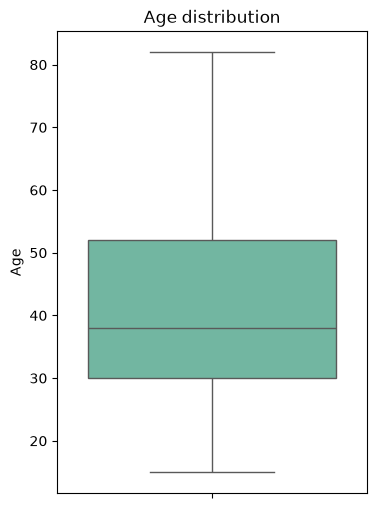

In [148]:
plt.figure(figsize=(4, 6))
plt.title('Age distribution')

sns.boxplot(data = df['Age'], palette='Set2')

plt.show()

1. The people in the sample are quite old (mean around 40, 50% are between 30 and 50 y.o.)
2. Most of them are women (near 80%)
3. There are little clue smoking is linked to tyroid cancer
4. Rate of recovery is large (around 70%)

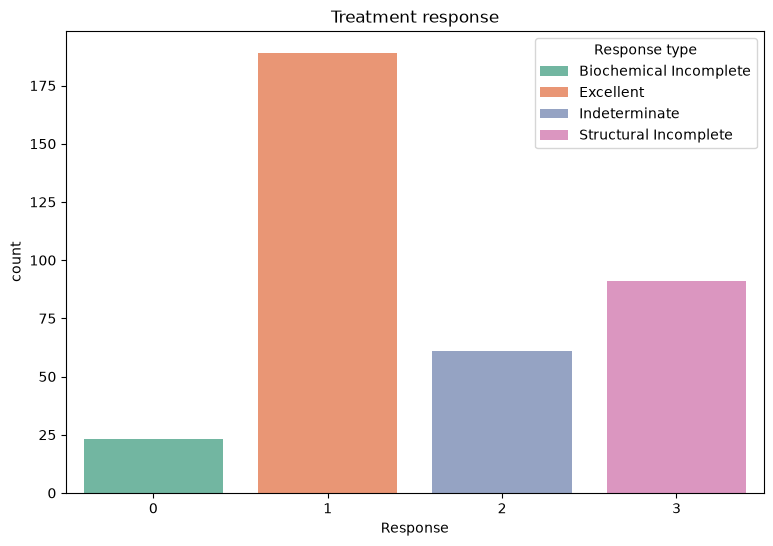

In [131]:
plt.figure(figsize=(9, 6))
plt.title('Treatment response')

sns.countplot(data=df, x='Response', hue = 'Response', palette='Set2')

response_labels = [
    'Biochemical Incomplete',
    'Excellent',
    'Indeterminate',
    'Structural Incomplete'
]
plt.legend(labels = response_labels, title = 'Response type')

plt.show()

Treatment response distribution tells us ~50% of the people get an excellent response to treatment, hence 50% have some kind of problem with it.
- Biochemical Incomplete (~6%) : Imaging tests show no abnormalities, but tumour markers in the blood remain detectable or abnormal. The disease is still active at a molecular level.
- Indeterminate (~15%) : The clinical or blood test results are inconclusive. This requires longer-term monitoring, but it is not yet clear whether the treatment has failed.
- Structural Incomplete (~25%) : The treatment is unsuitable or has failed. There is still physical and visible evidence of the disease.

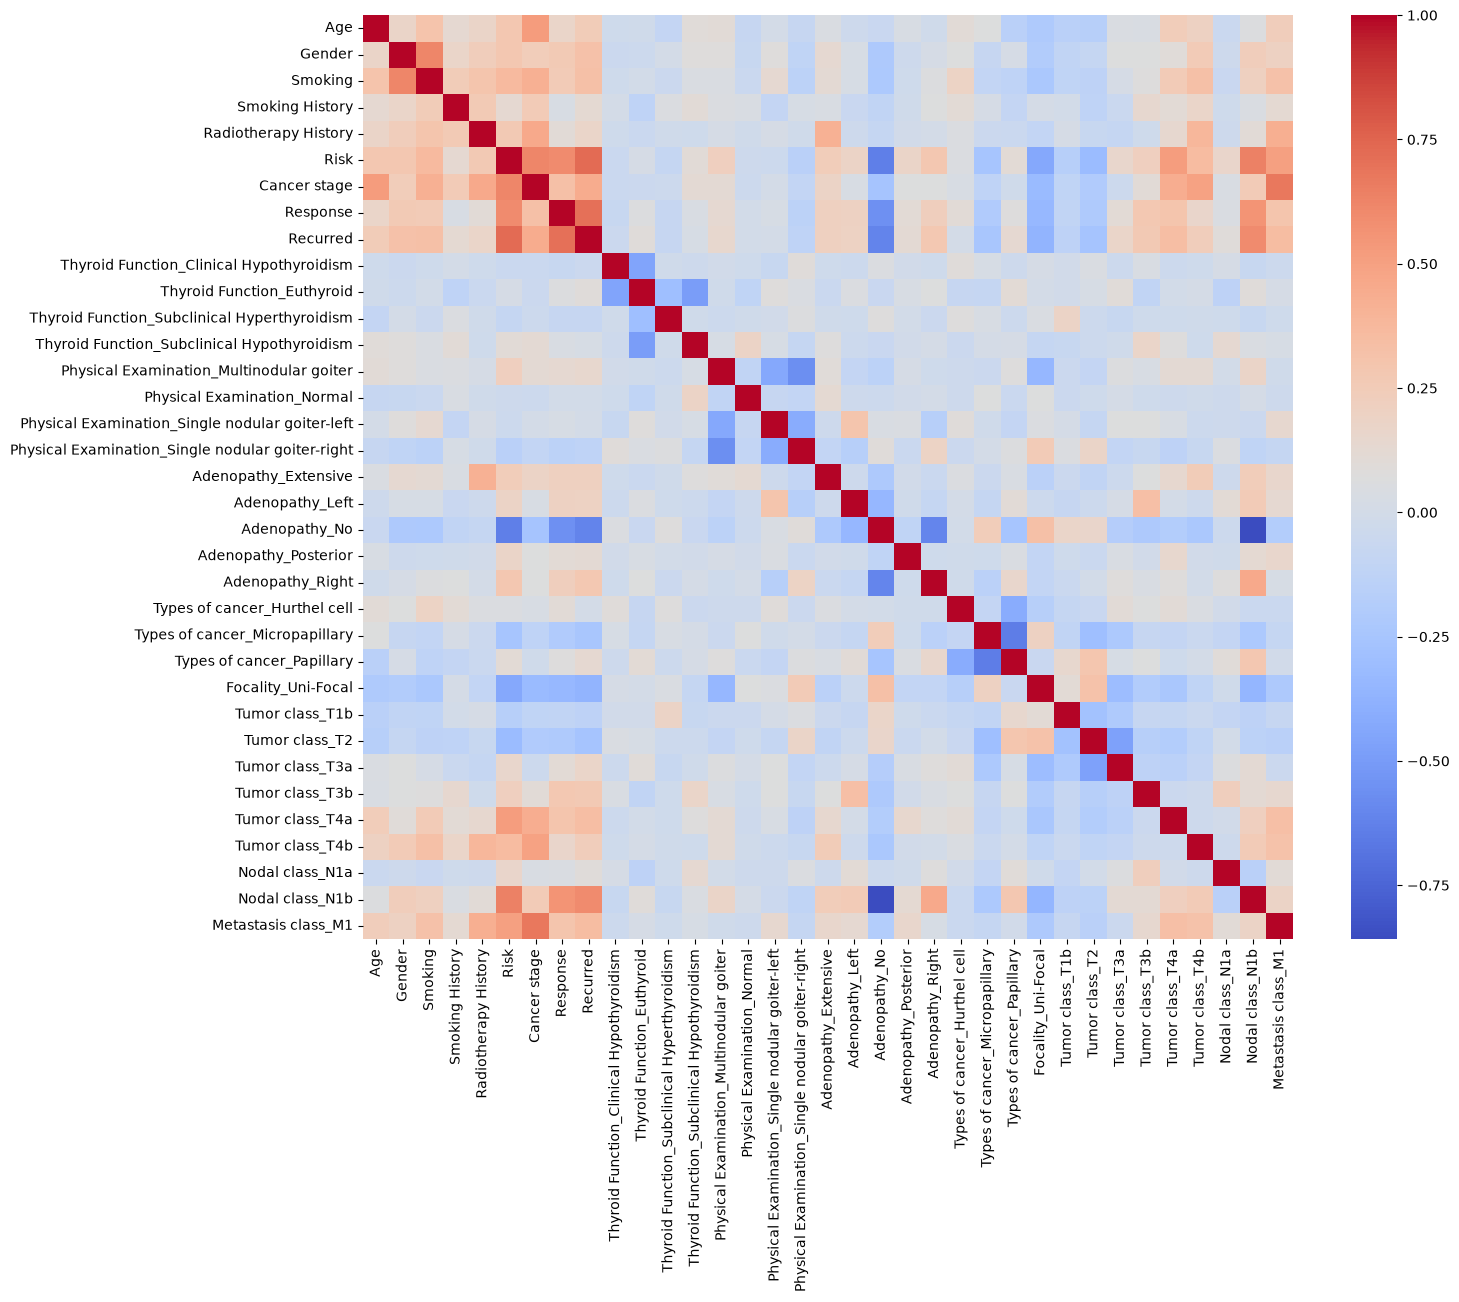

In [123]:
plt.figure(figsize=(15, 12))
sns.heatmap(df.corr(), cmap='coolwarm') ;

In [151]:
df.corr()['Response'].sort_values(ascending=False)

Response                                            1.000000
Recurred                                            0.702864
Risk                                                0.597216
Nodal class_N1b                                     0.560571
Cancer stage                                        0.331857
Metastasis class_M1                                 0.301301
Tumor class_T4a                                     0.296923
Tumor class_T3b                                     0.278450
Gender                                              0.261497
Smoking                                             0.254237
Adenopathy_Right                                    0.226829
Adenopathy_Extensive                                0.210063
Adenopathy_Left                                     0.206085
Age                                                 0.168765
Tumor class_T4b                                     0.164456
Physical Examination_Multinodular goiter            0.130869
Adenopathy_Posterior    

**Positive correlations** with ``Response`` :
We can see that ``Response`` turns distinctly red at the intersection of variables such as ``Risk`` (r = 0.6), ``Cancer stage`` (r = 0.33), ``Recurred`` (r = 0.70), ``Nodal class_N1b`` (r = 0.56, advanced lymph node stage) and ``Metastasis class_M1`` (r = 0.30, presence of metastases). This logically confirms that the more advanced and high-risk the cancer is, the more the ``Response`` tends to take on a high value (and thus tends towards an incomplete or inadequate response).

**Negative correlations** with ``Response``:
We see blue intersecting with ``Adenopathy_No`` (r = -0.56, no abnormal lymph nodes) and ``Focality_Uni-Focal`` (r = -0.34, tumour localised to a single site). This means that the absence of lymph node involvement and a single tumour are associated with a low value for your target variable (therefore, more likely an *Excellent* response).

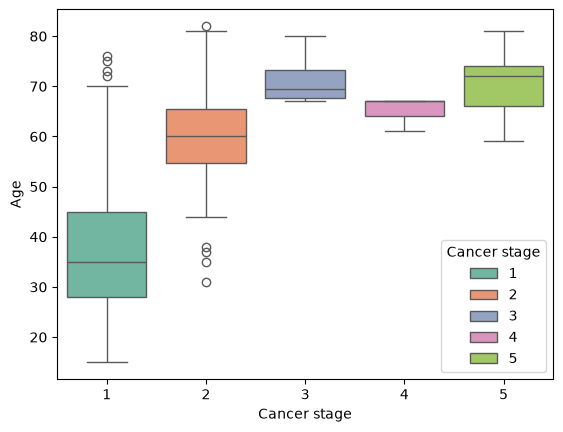

In [124]:
sns.boxplot(data=df, x='Cancer stage', y='Age', hue = 'Cancer stage', palette='Set2') ;